# AdaBoost Classification — Step by Step

**Dataset:** Breast Cancer Wisconsin (built into scikit-learn; no CSV download needed).

**Goal:** Predict malignant (`0`) or benign (`1`) from tumour measurements. This is a teaching example, **not** a clinical diagnostic tool.

We use a **Decision Stump** (`max_depth=1`) as the weak learner, just like our classroom example.


## Step 1 — Import the required libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay


## Step 2 — Load and inspect the dataset

569 records, 30 numeric input features. Target: `0 = malignant`, `1 = benign`.

In [3]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print('Shape of X:', X.shape)
print('Classes:', list(data.target_names))
display(X.head())
print('Target counts:')
print(y.value_counts())

Shape of X: (569, 30)
Classes: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Target counts:
target
1    357
0    212
Name: count, dtype: int64


## Step 3 — Divide the data into training and testing sets

`stratify=y` keeps approximately the same class proportions in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

Training rows: 455
Testing rows: 114


## Step 4 — Train ONE Decision Stump (baseline)

First, see how well a single weak learner performs. A stump has exactly one split, even though it can have two leaf nodes.

Single stump accuracy: 0.9211


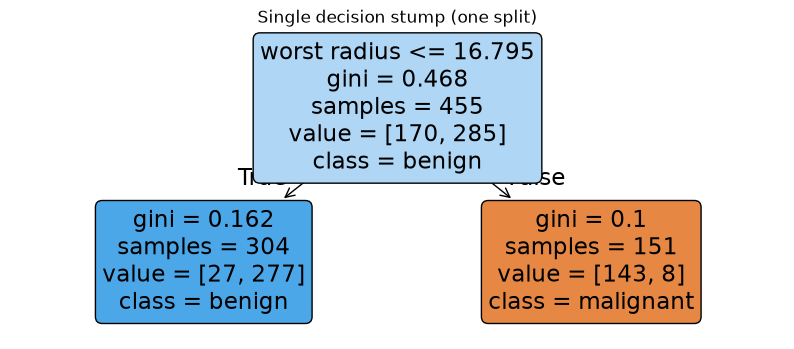

In [5]:
single_stump = DecisionTreeClassifier(max_depth=1, random_state=42)
single_stump.fit(X_train, y_train)

stump_predictions = single_stump.predict(X_test)
print('Single stump accuracy:', round(accuracy_score(y_test, stump_predictions), 4))

plt.figure(figsize=(10, 4))
plot_tree(single_stump, feature_names=X.columns,
          class_names=list(data.target_names), filled=True, rounded=True)
plt.title('Single decision stump (one split)')
plt.show()

## Step 5 — Train AdaBoost using Decision Stumps

AdaBoost trains multiple stumps **sequentially**. After each round, the training sample weights are adjusted so that incorrectly predicted examples receive more emphasis. You do **not** manually update the weights when using `AdaBoostClassifier`.

In [6]:
model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

model.fit(X_train, y_train)
print('Number of stumps actually trained:', len(model.estimators_))

Number of stumps actually trained: 50


## Step 6 — Predict and evaluate

AdaBoost accuracy: 0.9561

Classification report:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



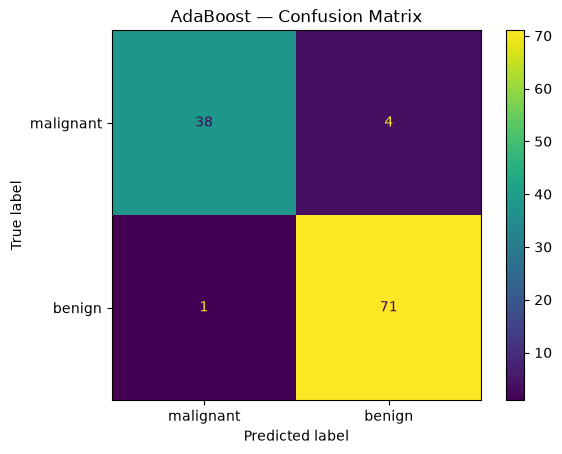

In [7]:
y_pred = model.predict(X_test)

print('AdaBoost accuracy:', round(accuracy_score(y_test, y_pred), 4))
print()
print('Classification report:')
print(classification_report(y_test, y_pred, target_names=data.target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=data.target_names
)
plt.title('AdaBoost — Confusion Matrix')
plt.show()

## Step 7 — Inspect weighted errors and stump importance

- `estimator_errors_` stores each stump's **weighted classification error**.
- `estimator_weights_` stores each stump's **voting weight**.
- These values are **not Gini impurity**. Gini is used **inside** each stump to choose its split.

**Formula note:** Current scikit-learn uses SAMME. For binary classification with `learning_rate=1`, its reported voting weight is `ln((1-error)/error)`, twice the `½ × ln((1-error)/error)` alpha used in our classic binary worked example. This factor does not change which class wins the combined weighted vote.


In [8]:
stump_details = pd.DataFrame({
    'Round': range(1, len(model.estimators_) + 1),
    'Weighted error': model.estimator_errors_[:len(model.estimators_)],
    'Voting weight': model.estimator_weights_[:len(model.estimators_)]
})
display(stump_details.head(10).round(4))

,Round,Weighted error,Voting weight
0,1,0.0769,2.4849
1,2,0.1488,1.7440
2,3,0.1410,1.8072
3,4,0.2167,1.2850
4,5,0.2731,0.9787
5,6,0.2050,1.3552
6,7,0.2374,1.1669
7,8,0.2515,1.0907
8,9,0.2706,0.9915
9,10,0.2889,0.9009


## Step 8 — Check performance with five-fold cross-validation

Cross-validation runs on **training data only**. Keep the test set for the final evaluation.

In [9]:
cv_scores = cross_val_score(
    model, X_train, y_train, cv=5, scoring='accuracy'
)
print('CV accuracy for each fold:', cv_scores.round(4))
print('Mean CV accuracy:', round(cv_scores.mean(), 4))

CV accuracy for each fold: [0.967  0.989  0.9231 0.978  0.989 ]
Mean CV accuracy: 0.9692


## Step 9 — OPTIONAL: GridSearchCV for AdaBoost parameters

Compare a few values of `n_estimators` and `learning_rate`. To keep this simple, we leave the base stump at `max_depth=1`.

In [10]:
param_grid = {
    'n_estimators': [30, 50, 100],
    'learning_rate': [0.1, 0.5, 1.0]
}

grid = GridSearchCV(
    estimator=AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        random_state=42
    ),
    param_grid=param_grid, cv=5, scoring='accuracy'
)
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best mean CV accuracy:', round(grid.best_score_, 4))
print('Tuned model test accuracy:', round(grid.score(X_test, y_test), 4))

Best parameters: {'learning_rate': 0.5, 'n_estimators': 100}
Best mean CV accuracy: 0.978
Tuned model test accuracy: 0.9561


## Parameters explained

| Parameter | Purpose |
|---|---|
| `estimator=DecisionTreeClassifier(max_depth=1)` | Make each weak learner a decision stump |
| `n_estimators=50` | Maximum number of boosting rounds (training can stop earlier) |
| `learning_rate=1.0` | Scales each stump's contribution |
| `random_state=42` | Helps reproduce results |
| `sample_weight` | AdaBoost manages this **internally** during successive fitting rounds |

**Takeaway:** Each stump sees the training dataset with updated sample weights. The stump chooses its split using **weighted Gini**; AdaBoost measures its **weighted classification error**, assigns its voting weight, and updates the sample weights for the following round.

Official reference: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html
